# 03 — HDB Resale Price Prediction

## Objective

This notebook aims to improve the prediction of Singapore HDB resale prices by comparing a Random Forest Regressor with the Multiple Linear Regression model developed in Notebook 2.

The analysis will:
1. Prepare the cleaned dataset for machine learning.
2. Train a Random Forest regression model.
3. Evaluate predictions using MAE, RMSE, and R².
4. Compare the Random Forest model against the Multiple Linear Regression model.
5. Interpret the results and identify potential limitations.

## Evaluation Approach

The models will be evaluated using a held-out test dataset. Lower MAE and RMSE indicate smaller prediction errors, while a higher R² indicates that the model explains more of the variation in resale prices.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
df = pd.read_csv("../data/hdb_resale_cleaned.csv")

print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape}")

df.head()

Dataset loaded successfully.
Dataset shape: (240807, 14)


,_id,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price,remaining_lease_numeric,price_per_sqm
0,1,2017-01-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.00,Improved,1979,61 years 04 months,"232,000.00",61.33,"5,272.73"
1,2,2017-01-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.00,New Generation,1978,60 years 07 months,"250,000.00",60.58,"3,731.34"
2,3,2017-01-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.00,New Generation,1980,62 years 05 months,"262,000.00",62.42,"3,910.45"
3,4,2017-01-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.00,New Generation,1980,62 years 01 month,"265,000.00",62.00,"3,897.06"
4,5,2017-01-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.00,New Generation,1980,62 years 05 months,"265,000.00",62.42,"3,955.22"


## 1. Understanding the Dataset

This analysis uses the cleaned HDB resale dataset prepared in Notebook 1. The dataset contains 240,807 resale transactions registered from January 2017 onwards.

The objective of this notebook is to build a Random Forest regression model and compare its predictive performance against the Multiple Linear Regression model developed in Notebook 2.

### 1.1 Selecting the Relevant Variables

The model will use the following variables to predict resale prices:

- **Floor area:** The size of the flat in square metres.
- **Remaining lease:** The estimated number of years remaining on the flat's lease.
- **Storey range:** The floor level range of the flat.
- **Flat type:** The classification of the flat, such as 3 ROOM or 4 ROOM.
- **Town:** The HDB town where the flat is located.

The target variable is `resale_price`, which represents the recorded resale transaction price.

The variable `price_per_sqm` will be excluded from the predictors because it is calculated directly from `resale_price` and `floor_area_sqm`. Including it could introduce target leakage and give the model information derived from the value it is supposed to predict.

The transaction identifier, block, street name, flat model, and lease commencement date will also be excluded from this initial model to keep the feature selection consistent with Notebook 2.

### 1.2 Checking Data Types and Missing Values

Before preparing the dataset for modelling, the data types and completeness of the selected variables are examined.

Machine-learning models require numerical inputs. Categorical variables, such as town and flat type, will therefore need to be encoded. Missing values must also be checked because they can affect model training and evaluation.

This step helps identify any data preparation requirements before the model is trained.

In [3]:
# Select the variables used in the model
features = [
    "floor_area_sqm",
    "remaining_lease_numeric",
    "storey_range",
    "flat_type",
    "town"
]

target = "resale_price"

# Inspect data types and missing values
model_data = df[features + [target]]

print("Data types:")
display(model_data.dtypes.to_frame(name="Data Type"))

print("\nMissing values:")
display(model_data.isnull().sum().to_frame(name="Missing Values"))

print("\nDataset shape:", model_data.shape)

Data types:


,Data Type
floor_area_sqm,float64
remaining_lease_numeric,float64
storey_range,str
flat_type,str
town,str
resale_price,float64



Missing values:


,Missing Values
floor_area_sqm,0
remaining_lease_numeric,0
storey_range,0
flat_type,0
town,0
resale_price,0



Dataset shape: (240807, 6)


## 2. Preparing the Data for Modelling

The dataset contains no missing values in the selected predictors or target variable. Therefore, no rows need to be removed due to missing data.

The predictors consist of two numerical variables and three categorical variables. These will be processed separately using a scikit-learn preprocessing pipeline:

- **Numerical variables:** Floor area and remaining lease will be standardised to place them on a comparable scale.
- **Categorical variables:** Storey range, flat type, and town will be converted into numerical representations using one-hot encoding.

A preprocessing pipeline ensures that the same transformations are applied consistently during model training and prediction.

### 2.1 Identifying Numerical and Categorical Variables

The predictors are separated into numerical and categorical groups because each type requires a different preprocessing method.

This separation also makes the modelling workflow easier to maintain and helps ensure that the transformations are applied to the correct variables.

In [4]:
# Separate numerical and categorical predictors
numerical_features = [
    "floor_area_sqm",
    "remaining_lease_numeric"
]

categorical_features = [
    "storey_range",
    "flat_type",
    "town"
]

X = model_data[features]
y = model_data[target]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Numerical features: ['floor_area_sqm', 'remaining_lease_numeric']
Categorical features: ['storey_range', 'flat_type', 'town']
Feature matrix shape: (240807, 5)
Target shape: (240807,)


### 2.2 Splitting the Dataset

The dataset is divided into training and testing sets using an 80:20 split.

The training set is used to fit the Random Forest model, while the testing set is reserved for evaluating its predictive performance on transactions that were not used during training.

The same `random_state=42` and split ratio used in Notebook 2 are retained to support a consistent comparison between the Random Forest and Multiple Linear Regression models.

In [5]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training transactions:", len(X_train))
print("Testing transactions:", len(X_test))

Training transactions: 192645
Testing transactions: 48162


### 2.3 Building the Preprocessing Pipeline

The numerical and categorical predictors require different transformations before they can be used by the model.

A `ColumnTransformer` applies the appropriate transformation to each group of variables. The numerical variables are standardised, while the categorical variables are converted using one-hot encoding.

These transformations are placed inside a scikit-learn pipeline. The preprocessing steps will be fitted using the training data only, helping prevent information from the test set from influencing model training.

Although scaling is not required by Random Forest, it is retained here to maintain a consistent preprocessing workflow with the previous analysis.

In [6]:
# Preprocess numerical and categorical variables
numerical_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline configured successfully.")

Preprocessing pipeline configured successfully.


## 3. Building the Random Forest Regression Model

Random Forest is an ensemble learning method that combines predictions from multiple decision trees. Each tree learns patterns from the training data, and their predictions are averaged to produce the final estimated resale price.

Unlike Multiple Linear Regression, which models relationships using a linear equation, Random Forest can capture more complex patterns and interactions between predictors.

The model will use the same five predictors selected in the previous sections. Its performance will then be evaluated using the same test dataset as Notebook 2.

### 3.1 Configuring the Random Forest Model

The model will use 100 decision trees, with a fixed random state to make the results reproducible.

The `n_jobs=-1` setting allows scikit-learn to use all available CPU cores during training. The remaining settings are kept at their defaults for this initial model, providing a baseline before any hyperparameter tuning.

In [7]:
# Configure the Random Forest regressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Combine preprocessing and model training into one pipeline
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", rf_model)
    ]
)

print("Random Forest pipeline configured successfully.")

Random Forest pipeline configured successfully.


### 3.2 Training the Random Forest Model

The Random Forest model is trained using the training dataset. During this process, the model learns patterns between the selected flat characteristics and their corresponding resale prices.

The testing dataset remains separate and will only be used to evaluate the model after training is complete.

In [8]:
# Train the Random Forest model
rf_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## 4. Evaluating Model Performance

After training, the Random Forest model is evaluated using the held-out testing dataset. This assesses how accurately the model predicts resale prices for transactions that were not used during training.

Three evaluation metrics are used:

- **Mean Absolute Error (MAE):** The average absolute difference between actual and predicted resale prices. A lower value indicates smaller prediction errors.
- **Root Mean Squared Error (RMSE):** Similar to MAE, but gives greater weight to larger prediction errors. A lower value indicates better performance.
- **R² Score:** Measures how much variation in resale prices is explained by the model relative to predicting the mean price. A score closer to 1 generally indicates better predictive performance.

These metrics will also allow the Random Forest model to be compared with the Multiple Linear Regression model developed in Notebook 2.

In [9]:
# Generate predictions for the test dataset
y_pred_rf = rf_pipeline.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

# Display results
print("Random Forest Model Performance")
print("-" * 35)
print(f"MAE:  ${rf_mae:,.2f}")
print(f"RMSE: ${rf_rmse:,.2f}")
print(f"R²:   {rf_r2:.4f}")

Random Forest Model Performance
-----------------------------------
MAE:  $47,504.78
RMSE: $69,414.86
R²:   0.8694


### 4.2 Interpreting the Results

The Random Forest model achieved an MAE of $47,504.78, an RMSE of $69,414.86, and an R² score of 0.8694 on the testing dataset.

The R² score indicates that the model explains approximately 86.94% of the variation in resale prices within the test set. The MAE suggests that the average absolute prediction error is approximately $47,505.

These results suggest that the Random Forest model captures useful patterns in the relationship between flat characteristics and resale prices. However, model performance should be assessed alongside the results from the Multiple Linear Regression model and the limitations of the dataset.

## 5. Comparing Random Forest and Multiple Linear Regression

The Random Forest model is compared with the Multiple Linear Regression model developed in Notebook 2. Both models use the same five predictors and the same 80:20 train-test split, allowing their predictive performance to be compared on the same testing transactions.

The comparison focuses on MAE, RMSE, and R². Lower MAE and RMSE values indicate smaller prediction errors, while a higher R² indicates that the model explains more variation in resale prices.

In [10]:
# Compare the two models using their test-set metrics
model_comparison = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        94051.74,
        rf_mae
    ],
    "RMSE": [
        115857.76,
        rf_rmse
    ],
    "R²": [
        0.6362,
        rf_r2
    ]
})

display(
    model_comparison.style.format({
        "MAE": "${:,.2f}",
        "RMSE": "${:,.2f}",
        "R²": "{:.4f}"
    })
)

,Model,MAE,RMSE,R²
0,Multiple Linear Regression,"$94,051.74","$115,857.76",0.6362
1,Random Forest,"$47,504.78","$69,414.86",0.8694


### 5.1 Interpreting the Model Comparison

The Random Forest model outperformed Multiple Linear Regression across all three evaluation metrics.

The MAE decreased from $94,051.74 to $47,504.78, representing an approximately 49.5% reduction in average absolute prediction error. The RMSE decreased from $115,857.76 to $69,414.86, a reduction of approximately 40.1%.

The R² score increased from 0.6362 to 0.8694, indicating that the Random Forest model explained a greater proportion of the variation in resale prices on the testing dataset.

These results suggest that the relationships between HDB resale prices and the selected predictors may be more complex than a linear model can capture. Random Forest can model nonlinear patterns and interactions between variables, which may help explain its improved performance.

However, the results apply to this particular test split. Further validation would be needed to assess how well the model generalises to other periods or unseen market conditions.

### 5.2 Visualising Prediction Errors

A bar chart is used to compare the MAE and RMSE of the two models. This provides a visual comparison of their prediction errors and highlights the extent to which Random Forest reduces errors relative to Multiple Linear Regression.

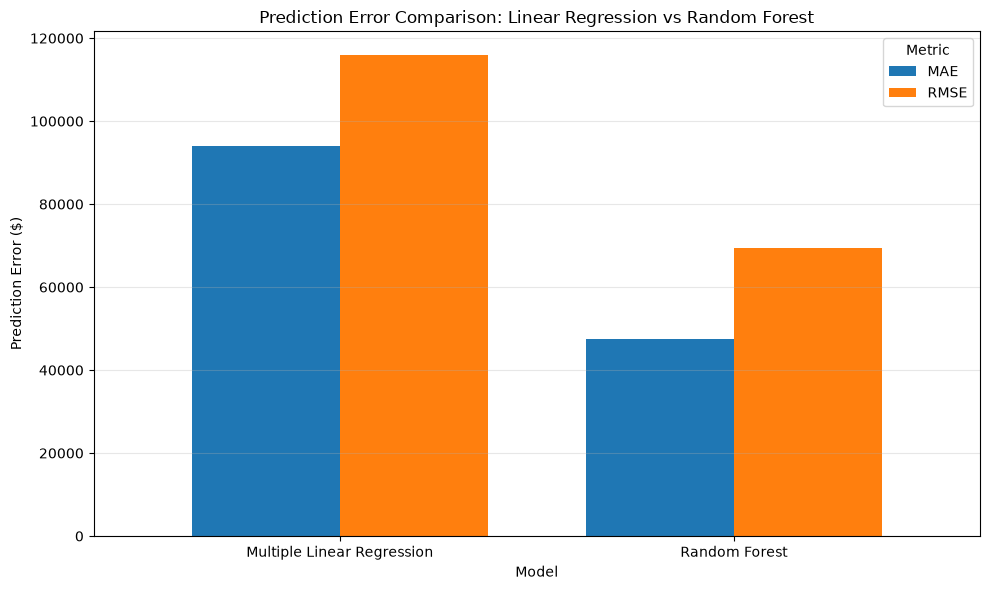

In [11]:
# Prepare model comparison for visualisation
error_comparison = model_comparison.set_index("Model")[["MAE", "RMSE"]]

ax = error_comparison.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.set_title("Prediction Error Comparison: Linear Regression vs Random Forest")
ax.set_xlabel("Model")
ax.set_ylabel("Prediction Error ($)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Metric")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Analysing Feature Importance

Feature importance helps identify which predictors the Random Forest model relied on most when making resale price predictions.

The model calculates importance scores based on how much each feature contributes to reducing prediction error across the decision trees. Higher scores indicate greater relative importance within this fitted model.

These scores describe predictive importance rather than causation. A feature with a high importance score should not automatically be interpreted as directly causing higher resale prices.

### 6.1 Extracting Feature Importance Scores

The preprocessing pipeline transforms the original predictors into numerical features, including one-hot encoded categories. The feature importance scores are extracted from the fitted Random Forest model and matched to the transformed feature names.

This allows the model's importance scores to be examined at the individual encoded-feature level.

In [12]:
# Retrieve the fitted preprocessing and Random Forest components
fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
fitted_rf = rf_pipeline.named_steps["model"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract and rank feature importance scores
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_rf.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.head(15))

,Feature,Importance
0,num__floor_area_sqm,0.42
1,num__remaining_lease_numeric,0.22
2,cat__town_BUKIT MERAH,0.04
3,cat__town_QUEENSTOWN,0.03
4,cat__town_TOA PAYOH,0.03
5,cat__town_KALLANG/WHAMPOA,0.02
6,cat__town_CENTRAL AREA,0.02
7,cat__town_BISHAN,0.02
8,cat__town_ANG MO KIO,0.01
9,cat__town_CLEMENTI,0.01


### 6.2 Visualising the Most Important Features

A horizontal bar chart is used to display the 15 features with the highest importance scores. This makes it easier to compare their relative contributions within the fitted Random Forest model.

The chart includes both numerical predictors and individual one-hot encoded categories. The importance scores sum to 1 across all transformed features, so the chart shows the relative importance of the selected features rather than their absolute effect on resale prices.

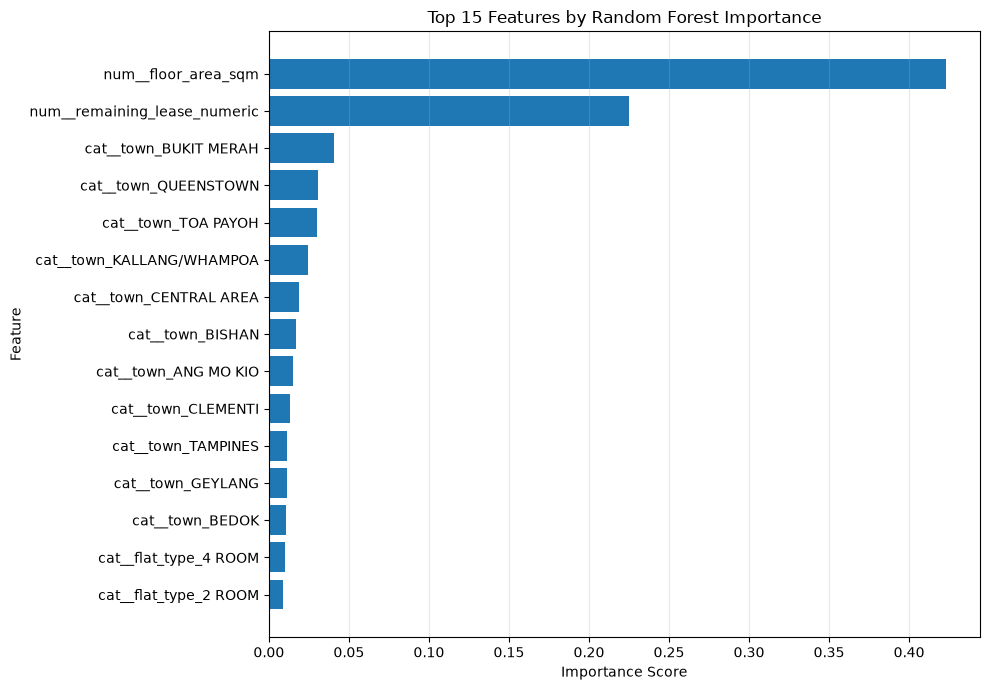

In [13]:
# Select the 15 most important features
top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

# Plot feature importance
fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_features["Feature"],
    top_features["Importance"]
)

ax.set_title("Top 15 Features by Random Forest Importance")
ax.set_xlabel("Importance Score")
ax.set_ylabel("Feature")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### 6.3 Interpreting Feature Importance

Floor area was the most important feature in the Random Forest model, with an importance score of approximately 0.42. Remaining lease was the second most important feature, with a score of approximately 0.22.

Together, these two numerical predictors account for approximately 64% of the model's total feature importance. This suggests that flat size and remaining lease provide substantial predictive information within the fitted model.

Several town categories, including Bukit Merah, Queenstown, and Toa Payoh, also appeared among the most important individual features. This indicates that location-related differences contribute to the model's predictions.

However, individual one-hot encoded categories should not be treated as the total importance of an entire variable. In addition, feature importance does not indicate whether a feature increases or decreases the predicted resale price, nor does it establish a causal relationship.

## 7. Overall Conclusion

This notebook developed a Random Forest regression model to predict Singapore HDB resale prices using floor area, remaining lease, storey range, flat type, and town.

The model achieved an MAE of $47,504.78, an RMSE of $69,414.86, and an R² score of 0.8694 on the held-out testing dataset.

Compared with Multiple Linear Regression, the Random Forest model reduced MAE by approximately 49.5% and RMSE by approximately 40.1%, while increasing R² from 0.6362 to 0.8694. These results suggest that Random Forest captured useful nonlinear patterns and interactions that the linear model may not have represented as effectively.

Feature-importance analysis identified floor area and remaining lease as the most important individual predictors in the fitted model. Several town categories also contributed to the model's predictions, highlighting the relevance of location.

### Limitations

Despite its stronger performance on the test set, the model has several limitations:

- The evaluation uses a random train-test split, so it does not directly measure how well the model predicts future transactions under changing market conditions.
- The model does not include every factor that may influence resale prices, such as proximity to MRT stations, nearby amenities, renovation condition, or broader economic conditions.
- Feature importance indicates predictive usefulness rather than causation.
- Further validation and hyperparameter tuning may improve the model or provide a more reliable estimate of its generalisation performance.

### Final Takeaway

The Random Forest model outperformed Multiple Linear Regression on the selected test dataset. This demonstrates the value of comparing different modelling approaches rather than assuming that a more interpretable linear model will always provide the most accurate predictions.